# Complexity analysis: analysis module

Here I analyze the algorithms of `src/analysis`: the cost of each line, the cost of the whole function, the optimized versions and the comparison of the times.

Sizes used:

* m: points of one curve (about 10)
* q: number of values where a curve is evaluated
* n: points of the integrator (201) and g: points of the grid of the derivative (191)
* N: curves of the table of features (940), d: number of features (13), K: number of classes (3)
* M: curves of the test set, S: number of sites (270)
* U: number of different scores in a ROC curve (U <= N)
* I: iterations of the fit and p: parameters of the model (4)
* c_s and d_m: curves and columns of the matrix of the covariance

In [1]:
import os
import sys
import timeit

sys.path.append(os.path.abspath(os.path.join("..", "..")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import GROUPS
from src.preprocessing.optimized import build_curve_data_groupby
from src.analysis import classification, matrix_ops
from src.analysis.curves import SoilRetentionCurve
from src.analysis.features import RetentionLevelFeatures, ShapeFeatures, VanGenuchtenFeatures
from src.analysis.metrics import roc_points
from src.analysis.group_stats import fisher_ratio
from src.analysis.optimized import roc_points_fast, fisher_ratio_fast, FastRetentionLevelFeatures


def measure(func, *args, repeats=3):
    return timeit.timeit(lambda: func(*args), number=repeats) / repeats


processed = os.path.join("..", "..", "data", "processed")
dataset = pd.read_csv(os.path.join(processed, "features.csv"), index_col="layer_id")
points_table = pd.read_csv(os.path.join(processed, "selected_points.csv"))
curve_data = build_curve_data_groupby(points_table)
print("curves:", len(curve_data), "| table of features:", dataset.shape)

curves: 940 | table of features: (940, 18)


## 1. Curves, calculus and the van Genuchten model

### SoilRetentionCurve

```python
class SoilRetentionCurve:
    """A measured curve: potential psi (m) and water content theta, sorted by psi."""

    def __init__(self, layer_id, psi, theta):
        """Save the data of the curve sorted by psi."""
        order = np.argsort(psi)
        self.layer_id = layer_id
        self.psi = np.array(psi)[order]
        self.theta = np.array(theta)[order]

    def theta_at(self, psi_values):
        """Interpolate theta at some values of psi."""
        return np.interp(psi_values, self.psi, self.theta)

    def theta_at_log(self, log_psi):
        """Interpolate theta at psi = 10 ** log_psi."""
        return self.theta_at(10 ** np.asarray(log_psi))
```

* `np.argsort(psi)`: O(m log m)
* `np.array(psi)[order]` and `np.array(theta)[order]`: O(m) each one
* the assignments: O(1)
* `theta_at`: `np.interp(...)` is O(q log m), each value is searched in the m sorted points
* `theta_at_log`: `10 ** log_psi` is O(q) and then `theta_at` is O(q log m)

**Total:** the constructor is O(m log m) in time and O(m) in space. `theta_at` and `theta_at_log` are O(q log m).

### Integrator and Trapezoidal

```python
class Trapezoidal(Integrator):
    """Trapezoidal rule."""

    def construct_method(self):
        """Return the points and the weights of the trapezoidal rule."""
        h = (self.b - self.a) / (self.n - 1)
        w = h * np.ones(self.n)
        w[0] = w[-1] = h / 2
        x = np.linspace(self.a, self.b, self.n)
        return x, w
```

* `Integrator.__init__`: the assignments are O(1)
* `h = (b - a) / (n - 1)`: O(1)
* `w = h * np.ones(n)`: O(n)
* `w[0] = w[-1] = h / 2`: O(1)
* `x = np.linspace(a, b, n)`: O(n)
* `integrate`: `f(self.points)` is O(n log m) when f is `theta_at_log`, and `self.weights @ ...` is O(n)

**Total:** building the rule is O(n). `integrate` is O(n log m), because the evaluation of f is the expensive part.

The code of `Integrator` (the base class) is:

```python
class Integrator:
    """Base class of the integration rules."""

    def __init__(self, a, b, n):
        """Build the points and the weights of the rule."""
        self.a, self.b, self.n = a, b, n
        self.points, self.weights = self.construct_method()

    def construct_method(self):
        """Return the points and the weights (it is defined in the child classes)."""
        pass

    def integrate(self, f):
        """Integrate the function f."""
        return self.weights @ f(self.points)
```

### ForwardDiff and CentralDiff

```python
class CentralDiff(Derivative):
    """Central difference."""

    def __call__(self, x):
        """Compute the derivative at x."""
        return (self.func(x + self.h) - self.func(x - self.h)) / (2 * self.h)
```

* `x + self.h` and `x - self.h`: O(g)
* `self.func(...)`: O(g log m) when func is `theta_at_log` (two calls in the central difference, one in the forward difference)
* the subtraction and the division: O(g)

**Total:** O(g log m) in time and O(g) in space. The central difference makes two evaluations and the forward difference only one, so the order is the same.

The code of `Derivative` (the base class) and `ForwardDiff` is:

```python
class Derivative:
    """Base class of the numerical derivatives."""

    def __init__(self, func, h=1e-4):
        """Save the function and the step h."""
        self.func = func
        self.h = h

class ForwardDiff(Derivative):
    """Forward difference."""

    def __call__(self, x):
        """Compute the derivative at x."""
        return (self.func(x + self.h) - self.func(x)) / self.h
```

### van_genuchten and VanGenuchtenModel

```python
class VanGenuchtenModel:
    """Van Genuchten model fitted to one curve."""

    def __init__(self):
        """Start without parameters."""
        self.params = None

    def fit(self, curve):
        """Fit alpha, n, theta_r and theta_s with curve_fit."""
        p0 = [1.0, 1.5, min(curve.theta.min(), 0.4), max(curve.theta.max(), 0.3)]
        lower = [0.001, 1.01, 0.0, 0.2]
        upper = [1000, 10.0, 0.5, 1.0]
        self.params, _ = curve_fit(van_genuchten, curve.psi, curve.theta, p0=p0, bounds=(lower, upper), maxfev=10000)
        return self

    def __call__(self, psi):
        """Evaluate the fitted curve."""
        return van_genuchten(psi, *self.params)

    def rmse(self, curve):
        """Root mean squared error of the fit."""
        return np.sqrt(np.mean((curve.theta - self(curve.psi)) ** 2))
```

* `van_genuchten(psi, ...)`: a fixed number of operations on q values, O(q)
* `fit`: `curve.theta.min()` and `max()` are O(m)
* `fit`: the lists p0, lower and upper are O(1)
* `fit`: `curve_fit(...)` is O(I m p^2). In each of the I iterations the model is evaluated on m points (p + 1 times for the Jacobian) and a least squares problem with an m x p matrix is solved
* `__call__`: O(q)
* `rmse`: the model on m points, the subtraction, the square, the mean and the square root are O(m)

**Total:** `fit` is O(I m p^2). I is not known before (it depends on the curve): the best case is a few iterations and the worst case is `maxfev` = 10000. With m = 10 and p = 4 the time depends mostly on I.

The code of `van_genuchten` is:

```python
def van_genuchten(psi, alpha, n, theta_r, theta_s):
    """Van Genuchten model with m = 1 - 1/n."""
    m = 1 - 1 / n
    return theta_r + (theta_s - theta_r) / (1 + (alpha * psi) ** n) ** m
```

## 2. Features

### RetentionLevelFeatures

```python
class RetentionLevelFeatures(FeatureExtractor):
    """Water content at some potentials and area under the curve."""
    domain = "retention level"
    psi_reference = [1, 3.3, 10, 33, 100]
    names = ["theta_1m", "theta_3p3m", "theta_10m", "theta_33m", "theta_100m", "area_theta_logpsi"]

    def extract(self, curve):
        """Return theta at 1, 3.3, 10, 33 and 100 m, and the area between 1 and 100 m."""
        values = list(curve.theta_at(self.psi_reference))
        area = Trapezoidal(0, 2, 201).integrate(curve.theta_at_log)
        return dict(zip(self.names, values + [area]))
```

* `curve.theta_at(self.psi_reference)` with 5 values: O(log m)
* `Trapezoidal(0, 2, 201)`: O(n)
* `.integrate(curve.theta_at_log)`: O(n log m)
* `dict(zip(...))`: O(1), only 6 items

**Total:** O(n log m). The integrator is built again for every curve.

### ShapeFeatures

```python
class ShapeFeatures(FeatureExtractor):
    """Slope of the curve."""
    domain = "curve shape"
    names = ["max_abs_slope", "log_psi_at_max_slope", "mean_abs_slope_dry"]

    def extract(self, curve):
        """Return the steepest slope, where it is and the mean slope in the dry range."""
        slope = CentralDiff(curve.theta_at_log, h=0.05)
        grid = np.linspace(0.05, 1.95, 191)
        steep = np.abs(slope(grid))
        return {"max_abs_slope": steep.max(),
                "log_psi_at_max_slope": grid[steep.argmax()],
                "mean_abs_slope_dry": steep[grid >= 1].mean()}
```

* `CentralDiff(curve.theta_at_log, h=0.05)`: O(1)
* `np.linspace(0.05, 1.95, 191)`: O(g)
* `np.abs(slope(grid))`: O(g log m)
* `steep.max()`, `steep.argmax()`: O(g)
* `steep[grid >= 1].mean()`: O(g)

**Total:** O(g log m).

### VanGenuchtenFeatures

```python
class VanGenuchtenFeatures(FeatureExtractor):
    """Parameters of the van Genuchten model."""
    domain = "van Genuchten parameters"
    names = ["log10_alpha", "n", "theta_r", "theta_s"]

    def extract(self, curve):
        """Fit the model and return its parameters. The error of the fit is also returned."""
        model = VanGenuchtenModel().fit(curve)
        alpha, n, theta_r, theta_s = model.params
        return {"log10_alpha": np.log10(alpha), "n": n, "theta_r": theta_r, "theta_s": theta_s,
                "vg_fit_rmse": model.rmse(curve)}
```

* `VanGenuchtenModel().fit(curve)`: O(I m p^2)
* the parameters and `np.log10(alpha)`: O(1)
* `model.rmse(curve)`: O(m)

**Total:** O(I m p^2).

### build_feature_table

```python
def build_feature_table(curve_data, extractors):
    """Apply all the extractors to all the curves. Returns a table with one row per curve."""
    table = {}
    for layer_id, (psi, theta) in curve_data.items():
        curve = SoilRetentionCurve(layer_id, psi, theta)
        values = {}
        for extractor in extractors:
            values.update(extractor.extract(curve))
        table[layer_id] = values
    feature_table = pd.DataFrame(table).T
    feature_table.index.name = "layer_id"
    return feature_table
```

* `for ... in curve_data.items()`: N iterations
* `SoilRetentionCurve(...)`: O(m log m)
* the loop over the 3 extractors and `values.update(...)`: the cost of `extract` of each one
* `table[layer_id] = values`: O(1)
* `pd.DataFrame(table).T`: O(N d)

**Total:** O(N (m log m + n log m + g log m + I m p^2)). The biggest term should be the fit, I check it in the section of the times.

The code of the base class `FeatureExtractor` is:

```python
class FeatureExtractor:
    """Base class of the extractors."""
    domain = "base"
    names = []

    def extract(self, curve):
        """Return a dictionary with the features of one curve (it is defined in the child classes)."""
        pass
```

## 3. Statistics by group

### summary_by_group

```python
def summary_by_group(dataset, features, groups):
    """Mean, median and variance of each feature in each group."""
    by_group = dataset.groupby("texture_group")[features]
    summary = {"mean": by_group.mean().loc[groups].T,
               "median": by_group.median().loc[groups].T,
               "variance": by_group.var().loc[groups].T}
    return summary
```

* `dataset.groupby("texture_group")[features]`: O(N d)
* `mean()` and `var()`: O(N d) each one
* `median()`: O(N d log N) in the worst case
* `.loc[groups].T`: O(K d)

**Total:** O(N d log N).

### find_outliers

```python
def find_outliers(dataset, features, groups):
    """Mark the outliers with the 1.5 IQR rule inside each group."""
    is_outlier = pd.DataFrame(False, index=dataset.index, columns=features)
    for group in groups:
        in_group = dataset["texture_group"] == group
        values = dataset.loc[in_group, features]
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        is_outlier.loc[in_group] = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    return is_outlier
```

* `pd.DataFrame(False, ...)`: O(N d)
* the loop has K iterations and each one makes `dataset["texture_group"] == group`: O(N)
* `values.quantile(0.25)` and `quantile(0.75)`: O(n_g d log n_g), n_g is the number of curves of the group
* the comparisons with `q1 - 1.5 * iqr` and the `|`: O(n_g d)
* `is_outlier.loc[in_group] = ...`: O(n_g d)

**Total:** O(N d log N).

### test_across_groups

```python
def test_across_groups(dataset, features, groups):
    """Shapiro-Wilk in each group. Then Kruskal-Wallis, or ANOVA if the three groups look normal."""
    alpha = 0.05
    alpha_bonferroni = alpha / len(features)
    results = {"min Shapiro p": [], "test used": [], "statistic": [], "p-value": [], "significant": []}
    for feature in features:
        samples = []
        shapiro_p = []
        for group in groups:
            sample = dataset.loc[dataset["texture_group"] == group, feature]
            samples.append(sample)
            shapiro_p.append(shapiro(sample).pvalue)

        if min(shapiro_p) < alpha:
            statistic, p_value = kruskal(*samples)
            name = "Kruskal-Wallis"
        else:
            statistic, p_value = f_oneway(*samples)
            name = "ANOVA"

        results["min Shapiro p"].append(min(shapiro_p))
        results["test used"].append(name)
        results["statistic"].append(statistic)
        results["p-value"].append(p_value)
        results["significant"].append(p_value < alpha_bonferroni)
    return pd.DataFrame(results, index=features), alpha_bonferroni
```

* the loop has d iterations
* K masks to get the samples: O(K N)
* `shapiro(sample)` for the K groups: O(n_g log n_g) each one
* `kruskal(...)`: O(N log N), it ranks all the values
* `pd.DataFrame(results, ...)`: O(d)

**Total:** O(d (K N + N log N)).

### fisher_ratio

```python
def fisher_ratio(values, labels, groups):
    """Fisher ratio: variance between groups divided by variance inside the groups."""
    overall_mean = values.mean()
    between = 0
    within = 0
    for group in groups:
        group_values = values[labels == group]
        between += len(group_values) * (group_values.mean() - overall_mean) ** 2
        within += len(group_values) * group_values.var(ddof=0)
    return between / within
```

* `values.mean()`: O(N)
* the loop has K iterations; `values[labels == group]` is O(N)
* `group_values.mean()` and `var()`: O(n_g)

**Total:** O(K N) for one feature.

### auc_one_vs_rest

```python
def auc_one_vs_rest(values, labels, group):
    """AUC of one feature for one group against the rest."""
    auc = roc_auc_score((labels == group).astype(int), values)
    return max(auc, 1 - auc)
```

* `labels == group` and `astype(int)`: O(N)
* `roc_auc_score(...)`: O(N log N), it sorts the scores

**Total:** O(N log N).

### separability_table

```python
def separability_table(dataset, features, groups):
    """Fisher ratio and AUC of each feature."""
    labels = dataset["texture_group"]
    table = pd.DataFrame(index=features)
    table["FDR"] = [fisher_ratio(dataset[f], labels, groups) for f in features]
    for group in groups:
        table["AUC " + group + " vs rest"] = [auc_one_vs_rest(dataset[f], labels, group) for f in features]
    return table
```

* d calls of `fisher_ratio`: O(d K N)
* d K calls of `auc_one_vs_rest`: O(d K N log N)

**Total:** O(d K N log N). The AUC is the biggest part.

## 4. Performance measures

### confusion_counts

```python
def confusion_counts(y_true, y_pred, classes):
    """Confusion matrix. Rows are the true classes and columns the predicted ones."""
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    for i, true_class in enumerate(classes):
        for j, pred_class in enumerate(classes):
            matrix[i, j] = np.sum((y_true == true_class) & (y_pred == pred_class))
    return matrix
```

* `np.zeros((K, K))`: O(K^2)
* the double loop: K^2 iterations
* `y_true == true_class`, `y_pred == pred_class`, `&` and `np.sum`: O(N) in each iteration

**Total:** O(K^2 N) in time and O(K^2 + N) in space.

The functions `se`, `sp`, `ppv` and `f1` have only a division, so they are O(1).

### per_class_metrics

```python
def per_class_metrics(matrix, classes):
    """Support, recall, specificity, precision and F1 of each class."""
    total = matrix.sum()
    table = {"support": [], "recall (Se)": [], "specificity (Sp)": [], "precision (PPV)": [], "F1": []}
    for i in range(len(classes)):
        tp = matrix[i, i]
        fn = matrix[i].sum() - tp
        fp = matrix[:, i].sum() - tp
        tn = total - tp - fn - fp
        table["support"].append(tp + fn)
        table["recall (Se)"].append(se(tp, fn))
        table["specificity (Sp)"].append(sp(tn, fp))
        table["precision (PPV)"].append(ppv(tp, fp))
        table["F1"].append(f1(tp, fn, fp))
    return pd.DataFrame(table, index=classes)
```

* the loop has K iterations
* `matrix[i].sum()` and `matrix[:, i].sum()`: O(K)
* `se`, `sp`, `ppv`, `f1` and the `append`: O(1)
* `pd.DataFrame(table, index=classes)`: O(K)

**Total:** O(K^2).

### roc_points (first version)

```python
def roc_points(scores, is_positive):
    """ROC curve. For each threshold all the scores are compared again."""
    thresholds = np.concatenate(([np.inf], np.unique(scores)[::-1]))
    tpr = []
    fpr = []
    for threshold in thresholds:
        predicted = scores >= threshold
        tpr.append(np.sum(predicted & is_positive) / np.sum(is_positive))
        fpr.append(np.sum(predicted & ~is_positive) / np.sum(~is_positive))
    return np.array(fpr), np.array(tpr)
```

* `np.unique(scores)`: O(N log N)
* `[::-1]` and `np.concatenate`: O(U)
* the loop has U + 1 iterations
* `scores >= threshold`: O(N) in each iteration
* `predicted & is_positive`, `np.sum(...)` and `np.sum(is_positive)`: O(N) in each iteration (the same with `~is_positive`)
* `np.array(fpr)` and `np.array(tpr)`: O(U)

**Total:** O(U N). If all the scores are equal (U = 1) it is O(N log N) (best case). If all are different (U = N) it is O(N^2) (worst case).

### auc_trapezoid

```python
def auc_trapezoid(fpr, tpr):
    """Area under the ROC curve with the trapezoidal rule."""
    auc = 0
    for i in range(1, len(fpr)):
        auc += (fpr[i] - fpr[i - 1]) * (tpr[i] + tpr[i - 1]) / 2
    return auc
```

* `auc = 0`: O(1)
* the loop has U - 1 iterations and each one has a few operations: O(1)

**Total:** O(U).

## 5. Classification

### split_by_site

```python
def split_by_site(table, test_fraction, seed):
    """Return a mask with the test curves. All the curves of a site go to the same set."""
    rng = np.random.RandomState(seed)
    sites = table["profile_id"].unique()
    mixed = rng.permutation(sites)
    test_sites = mixed[:int(round(test_fraction * len(sites)))]
    return table["profile_id"].isin(test_sites).values
```

* `np.random.RandomState(seed)`: O(1)
* `table["profile_id"].unique()`: O(N)
* `rng.permutation(sites)`: O(S)
* the slice of the test sites: O(S)
* `table["profile_id"].isin(test_sites)`: O(N + S)

**Total:** O(N + S).

### NearestCentroidClassifier

```python
class NearestCentroidClassifier:
    """Each class is represented by the mean of its curves. A curve goes to the closest mean."""

    def fit(self, X, y, classes):
        """Standardize the features and compute the centroids."""
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        Z = (X - self.mean) / self.std
        self.classes = np.array(classes)
        self.centroids = np.array([Z[y == c].mean(axis=0) for c in self.classes])
        return self

    def scores(self, X):
        """Minus the distance to each centroid. A higher value means closer."""
        Z = (X - self.mean) / self.std
        distances = np.zeros((len(Z), len(self.centroids)))
        for i, centroid in enumerate(self.centroids):
            distances[:, i] = np.sqrt(((Z - centroid) ** 2).sum(axis=1))
        return -distances

    def predict(self, X):
        """Class of the closest centroid."""
        return self.classes[np.argmax(self.scores(X), axis=1)]
```

* `fit`: `X.mean(axis=0)`, `X.std(axis=0)` and `Z = (X - mean) / std`: O(N d)
* `fit`: the loop over K classes, `y == c`: O(N) and `Z[...].mean(axis=0)`: O(n_c d)
* `scores`: `Z = (X - mean) / std`: O(M d)
* `scores`: the loop has K iterations; `(Z - centroid) ** 2`, `.sum(axis=1)` and `np.sqrt`: O(M d) in each one
* `predict`: `scores`, `np.argmax(axis=1)` and the indexing of the classes: O(K M d) + O(M K)

**Total:** `fit` is O(N d + K N). `scores` and `predict` are O(K M d) in time and O(M K) in space.

### evaluate_features

```python
def evaluate_features(dataset, columns, test_mask, groups):
    """Train with the train sites and test with the test sites. Returns accuracy, macro F1 and the baseline."""
    train = dataset[~test_mask]
    test = dataset[test_mask]
    model = NearestCentroidClassifier().fit(train[columns].values, train["texture_group"].values, groups)
    y_true = test["texture_group"].values
    y_pred = model.predict(test[columns].values)

    matrix = confusion_counts(y_true, y_pred, groups)
    table = per_class_metrics(matrix, groups)
    accuracy = np.trace(matrix) / matrix.sum()
    baseline = max(np.mean(y_true == c) for c in groups)
    return accuracy, table["F1"].mean(), baseline
```

* `dataset[~test_mask]` and `dataset[test_mask]`: O(N d)
* `fit(...)`: O(N d + K N)
* `predict(...)`: O(K M d)
* `confusion_counts(...)`: O(K^2 M)
* `per_class_metrics`, `np.trace`: O(K^2)
* the baseline `max(np.mean(y_true == c) ...)`: O(K M)

**Total:** O(N d + K M d + K^2 M).

### repeated_evaluation

```python
def repeated_evaluation(dataset, feature_sets, groups, n_splits=30):
    """Repeat evaluate_features with n_splits different splits for each set of features."""
    results = {"feature set": [], "seed": [], "accuracy": [], "macro F1": [], "majority baseline": []}
    for name, columns in feature_sets.items():
        for seed in range(n_splits):
            mask = split_by_site(dataset, 0.3, seed)
            accuracy, macro_f1, baseline = evaluate_features(dataset, columns, mask, groups)
            results["feature set"].append(name)
            results["seed"].append(seed)
            results["accuracy"].append(accuracy)
            results["macro F1"].append(macro_f1)
            results["majority baseline"].append(baseline)
    return pd.DataFrame(results)
```

* the two loops have (number of sets) x r iterations
* `split_by_site(...)` in each iteration: O(N + S)
* `evaluate_features(...)` in each iteration: O(N d + K M d + K^2 M)
* the `append`: O(1)

**Total:** O(sets r (N d + K M d + K^2 M + S)). The split with the same seed is computed again for each set of features.

## 6. Matrix operations

### curve_matrix

```python
def curve_matrix(curve_data, layer_ids, psi_grid):
    """Matrix with one row per curve: theta interpolated at the potentials of psi_grid."""
    rows = []
    for layer_id in layer_ids:
        psi, theta = curve_data[layer_id]
        curve = SoilRetentionCurve(layer_id, psi, theta)
        rows.append(curve.theta_at(psi_grid))
    return np.array(rows)
```

* the loop has c_s iterations
* `SoilRetentionCurve(...)`: O(m log m)
* `curve.theta_at(psi_grid)`: O(q log m)
* `np.array(rows)`: O(c_s q)

**Total:** O(c_s (m + q) log m).

### covariance_matrix

```python
def covariance_matrix(matrix):
    """Covariance matrix of the columns using a matrix product."""
    centered = matrix - matrix.mean(axis=0)
    return centered.T @ centered / (len(matrix) - 1)
```

* `matrix.mean(axis=0)` and the centering: O(n d_m)
* `centered.T @ centered`: O(n d_m^2)
* the division: O(d_m^2)

**Total:** O(n d_m^2).

### covariance_loop

```python
def covariance_loop(matrix):
    """Covariance matrix of the columns using loops."""
    n_rows, n_cols = matrix.shape
    means = [matrix[:, j].mean() for j in range(n_cols)]
    cov = np.zeros((n_cols, n_cols))
    for a in range(n_cols):
        for b in range(n_cols):
            total = 0
            for i in range(n_rows):
                total += (matrix[i, a] - means[a]) * (matrix[i, b] - means[b])
            cov[a, b] = total / (n_rows - 1)
    return cov
```

* the means: O(n d_m)
* the three loops (a, b, i): d_m^2 n iterations with O(1) operations

**Total:** O(n d_m^2), the same order as the matrix product but with Python loops.

### explained_variance

```python
def explained_variance(cov):
    """Eigenvalues of the covariance (from the largest) and the variance explained by each one."""
    eigenvalues, _ = scipy.linalg.eig(cov)
    eigenvalues = np.sort(eigenvalues.real)[::-1]
    return eigenvalues, eigenvalues / eigenvalues.sum()
```

* `scipy.linalg.eig(cov)`: O(d_m^3)
* `np.sort(...)[::-1]`: O(d_m log d_m)
* the division by the sum: O(d_m)

**Total:** O(d_m^3).

## 7. Optimization

I optimized the algorithms where the analysis showed a better order of growth or a repeated calculation (S7 session): the ROC curve, the Fisher ratio, the integrator of the features and the covariance. For each one I show the code, the cost of each line and the comparison with the first version.

### roc_points_fast (optimized)

```python
def roc_points_fast(scores, is_positive):
    """ROC curve. The scores are sorted once and then there is only one loop."""
    order = np.argsort(-scores)
    scores = scores[order]
    is_positive = is_positive[order]
    n_pos = is_positive.sum()
    n_neg = len(is_positive) - n_pos

    tp = 0
    fp = 0
    tpr = [0]
    fpr = [0]
    for i in range(len(scores)):
        if is_positive[i]:
            tp += 1
        else:
            fp += 1
        # a point is saved when the next score is different
        if i == len(scores) - 1 or scores[i + 1] != scores[i]:
            tpr.append(tp / n_pos)
            fpr.append(fp / n_neg)
    return np.array(fpr), np.array(tpr)
```

* `np.argsort(-scores)`: O(N log N)
* `scores[order]` and `is_positive[order]`: O(N)
* `is_positive.sum()` and the subtraction: O(N)
* the loop has N iterations; the `if`, the sums and the comparison are O(1); the `append` is O(1)
* `np.array(fpr)` and `np.array(tpr)`: O(U)

**Total:** O(N log N). The first version reads all the data for each threshold: O(U N), O(N^2) in the worst case. Here the number of positives above each threshold is counted while the sorted scores are read, so the data is read only once.

In [2]:
rng = np.random.RandomState(0)
sizes = [250, 500, 1000, 2000, 4000, 8000, 16000]
t_first = []
t_fast = []
for size in sizes:
    scores = rng.normal(size=size)
    is_positive = rng.rand(size) < 0.3
    t_first.append(measure(roc_points, scores, is_positive, repeats=1 if size >= 8000 else 3))
    t_fast.append(measure(roc_points_fast, scores, is_positive))

timing_roc = pd.DataFrame({"N": sizes, "first version (s)": t_first, "fast (s)": t_fast})
timing_roc["speed-up"] = timing_roc["first version (s)"] / timing_roc["fast (s)"]
timing_roc.round(5)

,N,first version (s),fast (s),speed-up
0,250,0.00443,0.00012,35.71329
1,500,0.00911,0.00021,43.79933
2,1000,0.02063,0.00079,26.02443
3,2000,0.05648,0.00118,47.83992
4,4000,0.09800,0.00162,60.51526
5,8000,0.30999,0.00524,59.20912
6,16000,0.96085,0.00772,124.51020


same ROC points (all scores different / repeated scores): [True, True]


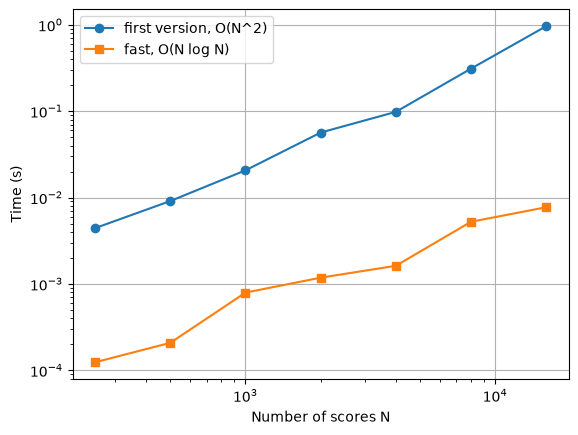

slope of the line (log-log), first version: 1.28 | fast: 1.01
speed-up with N = 16000 : 124.5 times


In [3]:
checks = []
rng = np.random.RandomState(1)
for decimals in [None, 1]:
    scores = rng.normal(size=500)
    if decimals is not None:
        scores = np.round(scores, decimals)
    is_positive = rng.rand(500) < 0.3
    a = roc_points(scores, is_positive)
    b = roc_points_fast(scores, is_positive)
    checks.append(np.allclose(a[0], b[0]) and np.allclose(a[1], b[1]))
print("same ROC points (all scores different / repeated scores):", checks)

plt.loglog(sizes, t_first, "o-", label="first version, O(N^2)")
plt.loglog(sizes, t_fast, "s-", label="fast, O(N log N)")
plt.xlabel("Number of scores N")
plt.ylabel("Time (s)")
plt.legend()
plt.grid(True)
plt.show()

slope_first = np.polyfit(np.log(sizes), np.log(t_first), 1)[0]
slope_fast = np.polyfit(np.log(sizes), np.log(t_fast), 1)[0]
print("slope of the line (log-log), first version:", round(slope_first, 2), "| fast:", round(slope_fast, 2))
print("speed-up with N =", sizes[-1], ":", round(t_first[-1] / t_fast[-1], 1), "times")

In the log-log plot the first version has a bigger slope than the fast one, as the analysis says (O(N^2) against O(N log N)). The slope of the first version is lower than 2 because, for small sizes, the fixed cost of each pandas/NumPy call is bigger than the O(N) work that each iteration does.

### fisher_ratio_fast (optimized)

```python
def fisher_ratio_fast(values, labels, groups):
    """Fisher ratio. The mean and the variance of the groups are computed with one groupby."""
    stats = values.groupby(labels).agg(["count", "mean", "var"])
    stats = stats.loc[groups]
    n = stats["count"]
    variance = stats["var"] * (n - 1) / n
    overall_mean = values.mean()
    between = (n * (stats["mean"] - overall_mean) ** 2).sum()
    within = (n * variance).sum()
    return between / within
```

* `values.groupby(labels).agg(["count", "mean", "var"])`: O(N), one pass
* `stats.loc[groups]`: O(K)
* `variance = stats["var"] * (n - 1) / n` (var with ddof = 0): O(K)
* `values.mean()`: O(N)
* `between` and `within`: O(K)

**Total:** O(N + K), against O(K N) of the first version, because the mean and the variance of all the groups are computed in one groupby (S6 session) and not with one mask per group.

In [4]:
labels = dataset["texture_group"]
differences = [abs(fisher_ratio(dataset[f], labels, GROUPS) - fisher_ratio_fast(dataset[f], labels, GROUPS)) for f in dataset.columns[:13]]
print("largest difference in the 13 features:", max(differences))

rng = np.random.RandomState(3)
sizes_fr = [1000, 4000, 16000, 64000, 256000]
t_first = []
t_fast = []
for size in sizes_fr:
    values = pd.Series(rng.normal(size=size))
    labs = pd.Series(rng.choice(GROUPS, size))
    t_first.append(measure(fisher_ratio, values, labs, GROUPS))
    t_fast.append(measure(fisher_ratio_fast, values, labs, GROUPS))

timing_fr = pd.DataFrame({"N": sizes_fr, "first version (s)": t_first, "fast (s)": t_fast})
timing_fr["speed-up"] = timing_fr["first version (s)"] / timing_fr["fast (s)"]
timing_fr.round(5)

largest difference in the 13 features: 1.1102230246251565e-15


,N,first version (s),fast (s),speed-up
0,1000,0.00067,0.00154,0.43655
1,4000,0.00151,0.00198,0.76146
2,16000,0.00323,0.00313,1.03098
3,64000,0.01408,0.00708,1.98932
4,256000,0.05238,0.02301,2.27695


For the smallest N the fast version is slower, because the groupby of pandas has a fixed cost. When N grows the fast version becomes better and the difference increases, as expected from O(N + K) against O(K N). With K = 3 groups the gain is not big.

### FastRetentionLevelFeatures (optimized)

```python
class FastRetentionLevelFeatures(RetentionLevelFeatures):
    """The same features, but the integrator is built only once."""

    def __init__(self):
        """Build the integrator."""
        self.integrator = Trapezoidal(0, 2, 201)

    def extract(self, curve):
        """Return theta at 1, 3.3, 10, 33 and 100 m, and the area between 1 and 100 m."""
        values = list(curve.theta_at(self.psi_reference))
        area = self.integrator.integrate(curve.theta_at_log)
        return dict(zip(self.names, values + [area]))
```

* `__init__`: `Trapezoidal(0, 2, 201)` is O(n) and it is done only once
* `extract`: `curve.theta_at(self.psi_reference)`: O(log m)
* `extract`: `self.integrator.integrate(...)`: O(n log m)
* `extract`: `dict(zip(...))`: O(1)

**Total:** O(n) once and O(n log m) for each curve. The first version builds the integrator (O(n)) for every curve. The order of growth is the same, O(C n log m), but I avoid a repeated calculation (S7 session).

In [5]:
curve_list = [SoilRetentionCurve(k, *curve_data[k]) for k in curve_data]
first_extractor = RetentionLevelFeatures()
fast_extractor = FastRetentionLevelFeatures()


def run_extractor(extractor, curves_to_use):
    return [extractor.extract(c) for c in curves_to_use]


sizes_c = [100, 200, 400, len(curve_list)]
t_first = [measure(run_extractor, first_extractor, curve_list[:k]) for k in sizes_c]
t_fast = [measure(run_extractor, fast_extractor, curve_list[:k]) for k in sizes_c]
print("same features:", run_extractor(first_extractor, curve_list) == run_extractor(fast_extractor, curve_list))
timing_ex = pd.DataFrame({"C": sizes_c, "first version (s)": t_first, "fast (s)": t_fast})
timing_ex["speed-up"] = timing_ex["first version (s)"] / timing_ex["fast (s)"]
timing_ex.round(5)

same features: True


,C,first version (s),fast (s),speed-up
0,100,0.00178,0.00084,2.12278
1,200,0.00351,0.00202,1.73969
2,400,0.00704,0.00398,1.76662
3,940,0.02019,0.00948,2.12944


### Covariance: matrix product and loops

Both are O(n d_m^2) (functions `covariance_matrix` and `covariance_loop` of the section 6), but the loops do all the operations in Python. It is the same comparison of the S2 session between `for` loops and `@`.

In [6]:
rng = np.random.RandomState(4)
sizes_cov = [100, 200, 400, 800]
t_loop = []
t_mat = []
for n_rows in sizes_cov:
    matrix = rng.normal(size=(n_rows, 8))
    t_loop.append(measure(matrix_ops.covariance_loop, matrix, repeats=2))
    t_mat.append(measure(matrix_ops.covariance_matrix, matrix))
print("same covariance:", np.allclose(matrix_ops.covariance_loop(matrix), matrix_ops.covariance_matrix(matrix)))
timing_cov = pd.DataFrame({"rows": sizes_cov, "loops (s)": t_loop, "matrix product (s)": t_mat})
timing_cov["speed-up"] = timing_cov["loops (s)"] / timing_cov["matrix product (s)"]
timing_cov.round(5)

same covariance: True


,rows,loops (s),matrix product (s),speed-up
0,100,0.00264,0.00004,72.11864
1,200,0.00489,0.00008,57.99545
2,400,0.01075,0.00010,112.46234
3,800,0.02098,0.00005,408.48767


## 8. Where is the time? Time of each extractor

According to the analysis, the fit of the van Genuchten model should be the biggest part of the time of `build_feature_table`. I measure each extractor with the first 100 curves.

retention level     0.3
curve shape         0.4
van Genuchten      99.2
dtype: float64


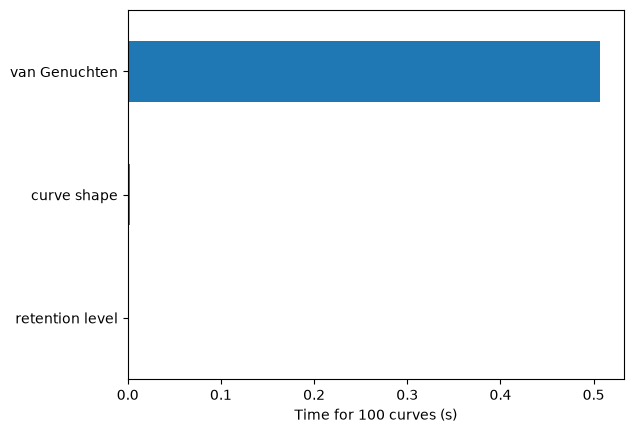

In [7]:
sub = curve_list[:100]
t_ret = measure(run_extractor, RetentionLevelFeatures(), sub, repeats=1)
t_shape = measure(run_extractor, ShapeFeatures(), sub, repeats=1)
t_vg = measure(run_extractor, VanGenuchtenFeatures(), sub, repeats=1)
times = pd.Series({"retention level": t_ret, "curve shape": t_shape, "van Genuchten": t_vg})
print((100 * times / times.sum()).round(1))
times.plot.barh()
plt.xlabel("Time for 100 curves (s)")
plt.show()

The extractors that only interpolate are O(n log m) and O(g log m) and they are very fast. The extractor that calls `curve_fit` takes almost all the time. Because of this, the optimization of the integrator changes very little the total time. The fits of different curves do not depend on each other, so they could be done in parallel, but I did not implement it because it is out of the content of the course.

## 9. Summary

| Algorithm | First version | Optimized |
|---|---|---|
| `SoilRetentionCurve` | O(m log m) | |
| `theta_at`, `theta_at_log` | O(q log m) | |
| `Trapezoidal` (rule / integrate) | O(n) / O(n log m) | |
| `ForwardDiff`, `CentralDiff` | O(g log m) | |
| `VanGenuchtenModel.fit` | O(I m p^2) | |
| `RetentionLevelFeatures` | O(n log m) | same order, the integrator is built once |
| `ShapeFeatures` | O(g log m) | |
| `VanGenuchtenFeatures` | O(I m p^2) | |
| `build_feature_table` | O(N (n log m + g log m + I m p^2)) | |
| `summary_by_group`, `find_outliers` | O(N d log N) | |
| `test_across_groups` | O(d (K N + N log N)) | |
| `fisher_ratio` | O(K N) | O(N + K) |
| `separability_table` | O(d K N log N) | |
| `confusion_counts` | O(K^2 N) | |
| `per_class_metrics` | O(K^2) | |
| `roc_points` | O(U N), O(N^2) in the worst case | O(N log N) |
| `auc_trapezoid` | O(U) | |
| `split_by_site` | O(N + S) | |
| `NearestCentroidClassifier` | fit O(N d + K N), predict O(K M d) | |
| `evaluate_features` | O(N d + K M d + K^2 M) | |
| `repeated_evaluation` | O(sets r (N d + K M d + K^2 M + S)) | |
| `curve_matrix` | O(c_s (m + q) log m) | |
| `covariance` | O(n d_m^2) with loops | O(n d_m^2) with a matrix product |
| `explained_variance` | O(d_m^3) | |